# 03 · Nube de palabras (Beyond)

Toma la columna B de los archivos de gastos (la descripción de cada registro), arma una nube de palabras por miembro y busca cuál es el deporte favorito de cada uno. Usa agosto y septiembre.

In [1]:
import re
import subprocess
import sys
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    from wordcloud import WordCloud
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wordcloud"], check=True)
    from wordcloud import WordCloud

REPO_URL = "https://github.com/Juangonzalez09/Technical-Test-IW.git"

if "google.colab" in sys.modules:
    RAIZ = Path("Technical-Test-IW")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
else:
    RAIZ = Path("..")

BRONZE = RAIZ / "data" / "bronze"

## Descripciones

Se lee la columna B de cada archivo tal como viene. Se excluyen los contratos, porque son ingresos y no dicen nada de los gustos de cada uno.

In [2]:
def leer_descripciones(carpeta):
    """Columna B (descripción) y E (categoría) de cada archivo de gastos, con el miembro que la registró."""
    partes = []
    for ruta in sorted(carpeta.glob("Gastos_*")):
        miembro = ruta.stem.split("_")[1]
        if ruta.suffix == ".txt":
            df = pd.read_csv(ruta, sep=";", quotechar="'", dtype=str)
        else:
            df = pd.read_excel(ruta, dtype=str)
        partes.append(pd.DataFrame({"miembro": miembro, "descripcion": df.iloc[:, 1], "categoria": df.iloc[:, 4]}))
    return pd.concat(partes, ignore_index=True)


descripciones = leer_descripciones(BRONZE)
descripciones = descripciones[~descripciones["categoria"].str.lower().str.startswith("contrato")]
display(descripciones.head())
descripciones.groupby("miembro").size().rename("registros")

,miembro,descripcion,categoria
1,Hijo,helados casa,COMIDAS AFUERA
2,Hijo,cafe americano,COMIDAS AFUERA
3,Hijo,cafe,COMIDAS AFUERA
4,Hijo,Cafe Tostado,COMIDAS AFUERA
5,Hijo,Compra en la gata restaurante poblado,COMIDAS AFUERA


miembro
Hijo     55
Mama     71
Papa    241
Name: registros, dtype: int64

## Limpieza de palabras

Minúsculas, sin tildes, sin números y sin palabras que no aportan (`de`, `con`, `para`…). También se quitan `mama` y `papa`: en descripciones como "almuerzo mama" dicen para quién fue el gasto, no en qué.

In [3]:
VACIAS = {"del", "las", "los", "con", "para", "por", "una", "mama", "papa", "pago"}


def palabras(texto):
    """Palabras de una descripción: minúsculas, sin tildes, sin números ni palabras vacías."""
    texto = unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()
    return [p for p in re.findall(r"[a-z]+", texto) if len(p) > 2 and p not in VACIAS]


descripciones["palabras"] = descripciones["descripcion"].fillna("").map(palabras)

## Nube por miembro

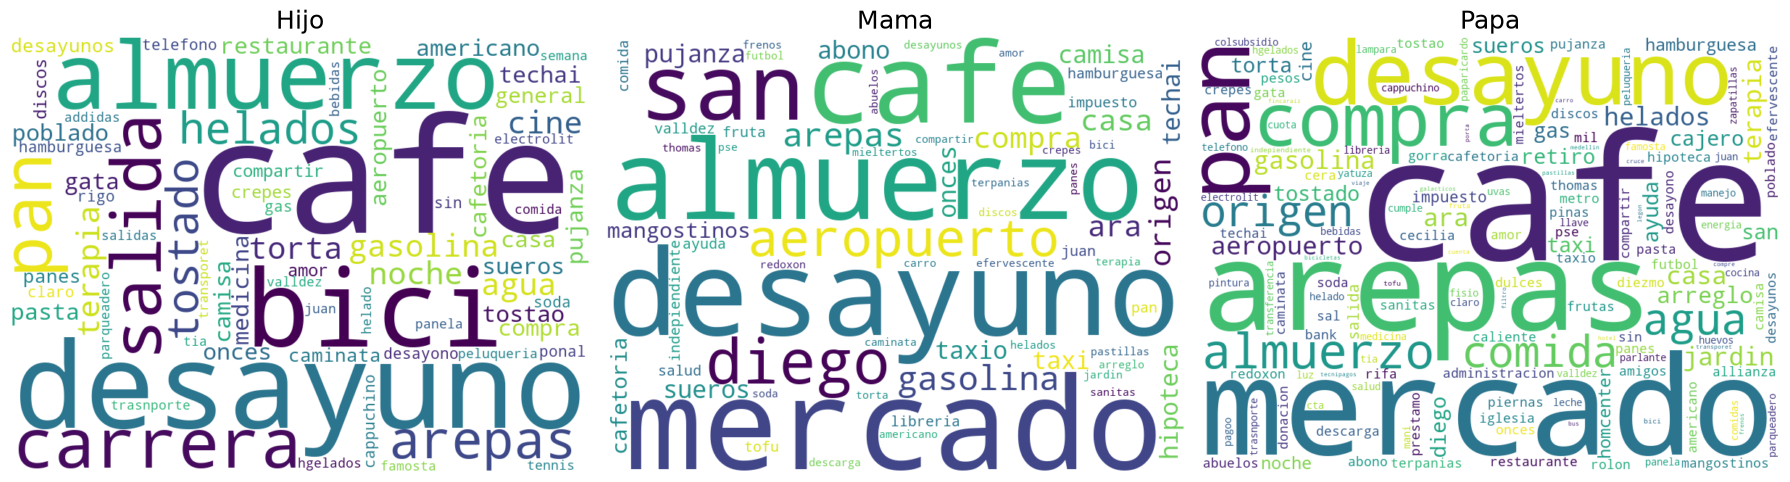

In [4]:
miembros = sorted(descripciones["miembro"].unique())
fig, ejes = plt.subplots(1, len(miembros), figsize=(18, 6))

for eje, miembro in zip(ejes, miembros):
    frecuencias = Counter(p for lista in descripciones.loc[descripciones["miembro"] == miembro, "palabras"] for p in lista)
    nube = WordCloud(width=800, height=600, background_color="white", colormap="viridis", random_state=1)
    eje.imshow(nube.generate_from_frequencies(frecuencias), interpolation="bilinear")
    eje.set_title(miembro, fontsize=18)
    eje.axis("off")

plt.tight_layout()
plt.show()

## ¿Deporte favorito?

En la nube dominan los gastos del día a día (café, mercado, almuerzo), porque son los más frecuentes. Para responder la pregunta se cuentan las palabras relacionadas con deporte en las descripciones de cada miembro:

In [5]:
DEPORTES = {
    "Ciclismo": {"bici", "bicicleta", "bicicletas"},
    "Carreras": {"carrera"},
    "Caminata": {"caminata"},
    "Fútbol": {"futbol"},
}

conteo = pd.DataFrame({
    deporte: descripciones.groupby("miembro")["palabras"].apply(
        lambda listas: sum(p in claves for lista in listas for p in lista)
    )
    for deporte, claves in DEPORTES.items()
})
conteo

,Ciclismo,Carreras,Caminata,Fútbol
miembro,,,,
Hijo,4,3,1,0
Mama,1,0,1,1
Papa,3,0,2,2


Las descripciones que tienen esas palabras:

In [6]:
claves = set().union(*DEPORTES.values())
deportivas = descripciones[descripciones["palabras"].map(lambda lista: bool(claves & set(lista)))]
deportivas[["miembro", "descripcion", "categoria"]].drop_duplicates().sort_values(["miembro", "descripcion"])

,miembro,descripcion,categoria
18,Hijo,Cafe y torta caminata,COMIDAS AFUERA
22,Hijo,Carrera de ponal,DEPORTE ENTRENO + INSCRIPCIONES
28,Hijo,Carrera go rigo,DEPORTE ENTRENO + INSCRIPCIONES
41,Hijo,Salidas en bici de la semana,DEPORTE ENTRENO + INSCRIPCIONES
12,Hijo,carrera de bici,DEPORTE ENTRENO + INSCRIPCIONES
17,Hijo,salida en bici,DEPORTE ENTRENO + INSCRIPCIONES
40,Hijo,transporet salida bici,DEPORTE ENTRENO + INSCRIPCIONES
105,Mama,Cafe y torta caminata,COMIDAS AFUERA
104,Mama,Pastillas frenos bici,DEPORTE ENTRENO + INSCRIPCIONES
97,Mama,ayuda futbol thomas,OFRENDAS FAMILIA


## Conclusión

**El deporte de la familia es el ciclismo.**

- **Hijo: ciclismo, sin duda.** "bici", "carrera" y "salida" están entre las palabras más grandes de su nube. Todos sus registros deportivos son de bici: carrera de bici, salidas en bici, inscripciones a carreras (Go Rigo, Ponal) y transporte para salir en bici. Es además quien más gasta en `DEPORTE ENTRENO + INSCRIPCIONES` en septiembre.
- **Papá: ciclismo.** Compró un porta bicicletas, pastillas de frenos para la bici y pagó transporte para una salida en bici.
- **Mamá: no hay señal propia.** Su único registro de deporte ("Pastillas frenos bici") es el mismo de papá, con la misma fecha y el mismo valor, uno de los registros repetidos entre miembros (ver `01_etl`, sección 5).

Palabras que parecen deporte pero no lo son:

- **"fútbol"** solo aparece en "ayuda futbol thomas", una ayuda económica a otra persona (rubro `OFRENDAS FAMILIA`).
- **"caminata"** viene de "Cafe y torta caminata", un gasto de comida repetido en los tres archivos.
- **"tennis addidas"** del hijo son zapatillas (rubro `ROPA`), no el deporte.